# Stop-Line and Motorcycle Crossing Analysis

## Experiment objective

This notebook independently explores how to identify a motorcycle crossing a configured stop line using its movement across consecutive video frames. It is an **experimental notebook**, not part of the production application.

The notebook:
1. Displays a video frame so the stop line can be configured visually.
2. Loads the tracking CSV produced by the separate motorcycle-tracking experiment.
3. Uses the bottom-centre of each bounding box as the motorcycle's ground-contact reference point.
4. Checks whether the reference point changes sides of the finite stop-line segment.
5. Visualizes trajectories and candidate crossing points.

> A geometric crossing is not, by itself, a red-light violation. Signal phase, direction, timestamp accuracy, and evidence quality must be checked separately.

## Import experiment dependencies

In [3]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

VIDEO_PATH = Path("../data/raw/video.mp4")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)

TRACKS_CSV = Path.joinpath(OUTPUT_DIR, "tracks_botsort.csv")

MIN_TRACK_OBSERVATIONS = 3

print("Video:", VIDEO_PATH.resolve())
print("Tracking CSV:", TRACKS_CSV.resolve())

Video: C:\Users\Pasidu\OneDrive\Documents\Developments\AI\Projects\Assignments\motosignal-ai\data\raw\video.mp4
Tracking CSV: C:\Users\Pasidu\OneDrive\Documents\Developments\AI\Projects\Assignments\motosignal-ai\notebooks\outputs\tracks_botsort.csv


## Inspect a frame and configure the stop line

The line coordinates above are normalized, so they remain independent of image resolution. Adjust the endpoints to match the visible stop line in the CCTV scene. Use the same physical road marking throughout the experiment.

Video: 2568x1440, 30.00 FPS, 950 frames


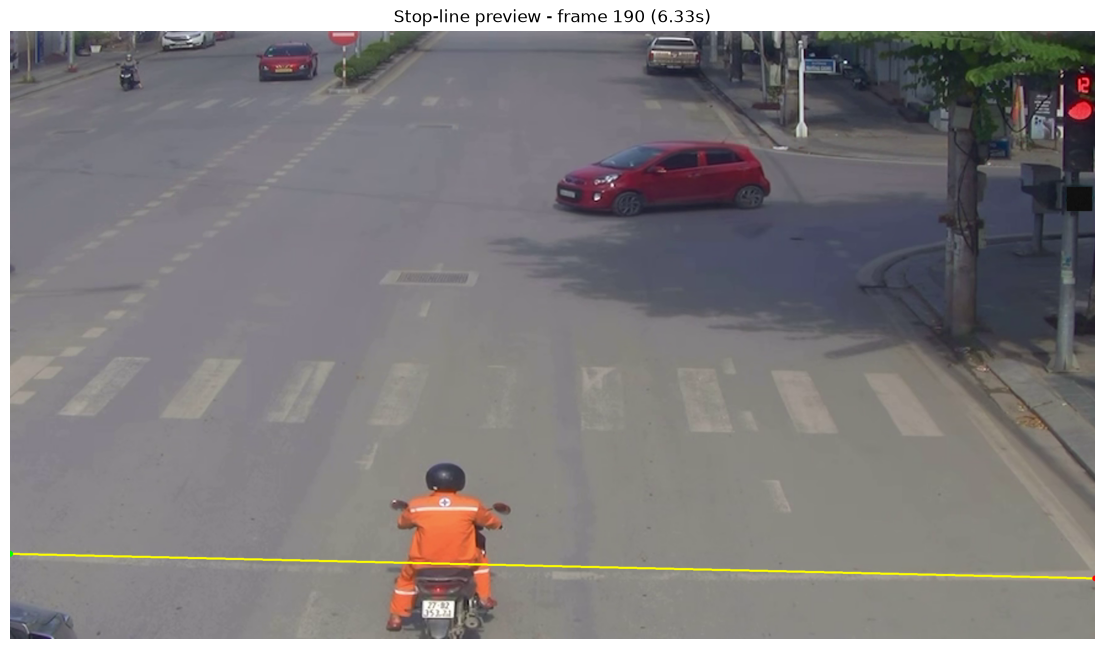

In [12]:
assert VIDEO_PATH.exists(), f"Video not found: {VIDEO_PATH}. Update VIDEO_PATH."

# Stop-line endpoints as normalized image coordinates (x, y), each in [0, 1].
# Change these after inspecting the preview below.
LINE_START = (0.00, 0.86)
LINE_END   = (1.00, 0.90)

cap = cv2.VideoCapture(str(VIDEO_PATH))
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS) or 25.0
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Choose a frame where the stop line is clearly visible.
PREVIEW_FRAME = min(max(frame_count // 5, 0), max(frame_count - 1, 0))

cap.set(cv2.CAP_PROP_POS_FRAMES, PREVIEW_FRAME)
ok, frame = cap.read()
cap.release()
assert ok, "Could not read the selected preview frame."

line_px_start = (int(LINE_START[0] * width), int(LINE_START[1] * height))
line_px_end = (int(LINE_END[0] * width), int(LINE_END[1] * height))

preview = frame.copy()
cv2.line(preview, line_px_start, line_px_end, (0, 255, 255), 4)
cv2.circle(preview, line_px_start, 7, (0, 255, 0), -1)
cv2.circle(preview, line_px_end, 7, (0, 0, 255), -1)

print(f"Video: {width}x{height}, {fps:.2f} FPS, {frame_count} frames")

plt.figure(figsize=(14, 8))
plt.imshow(cv2.cvtColor(preview, cv2.COLOR_BGR2RGB))
plt.title(f"Stop-line preview - frame {PREVIEW_FRAME} ({PREVIEW_FRAME / fps:.2f}s)")
plt.axis("off")
plt.show()

## Load the tracking experiment output

This notebook reads the CSV generated by the earlier tracking experiment.

In [13]:
assert TRACKS_CSV.exists(), (
    f"Tracking CSV not found: {TRACKS_CSV}. Run notebook 03 first, "
    "then update TRACKS_CSV to the generated CSV filename."
)

tracks = pd.read_csv(TRACKS_CSV)
required_columns = {"frame", "time_sec", "track_id", "x1", "y1", "x2", "y2"}
missing = required_columns - set(tracks.columns)

assert not missing, f"Tracking CSV is missing columns: {sorted(missing)}"

# Bottom-centre is used as an approximate ground-contact anchor
tracks["anchor_x"] = (tracks["x1"] + tracks["x2"]) / 2.0
tracks["anchor_y"] = tracks["y2"]
tracks = tracks.sort_values(["track_id", "frame"]).reset_index(drop=True)

print(f"Loaded {len(tracks):,} observations from {tracks['track_id'].nunique()} track IDs.")
display(tracks.head())

Loaded 6,055 observations from 101 track IDs.


,frame,time_sec,track_id,x1,y1,x2,y2,confidence,center_x,center_y,anchor_x,anchor_y
0,0,0.000000,1,894.135986,1083.506836,1185.200684,1440.000000,0.453244,1039.668335,1261.753418,1039.668335,1440.000000
1,1,0.033333,1,896.929504,1088.008789,1185.774536,1439.999756,0.429413,1041.352020,1264.004272,1041.352020,1439.999756
2,2,0.066667,1,897.106567,1086.749634,1185.619141,1440.000000,0.431080,1041.362854,1263.374817,1041.362854,1440.000000
3,3,0.100000,1,897.143311,1085.896240,1185.324341,1439.999146,0.434110,1041.233826,1262.947693,1041.233826,1439.999146
4,4,0.133333,1,895.982544,1073.613892,1185.877686,1440.000000,0.393255,1040.930115,1256.806946,1040.930115,1440.000000


## Implement line-crossing geometry inside this notebook

A candidate crossing is recorded when two consecutive anchor positions lie on opposite sides of the infinite line **and** their connecting movement segment intersects the configured finite stop-line segment. The crossing time is estimated by linear interpolation between the two observations.

In [14]:
def cross2d(a, b):
    """2D scalar cross product."""
    return a[0] * b[1] - a[1] * b[0]

def segment_intersection_parameters(p, p_next, line_start, line_end, eps=1e-9):
    """Return (movement_fraction, line_fraction) if two finite segments intersect."""
    p = np.asarray(p, dtype=float)
    r = np.asarray(p_next, dtype=float) - p
    q = np.asarray(line_start, dtype=float)
    s = np.asarray(line_end, dtype=float) - q
    denominator = cross2d(r, s)
    
    if abs(denominator) < eps:
        return None
    
    q_minus_p = q - p
    t = cross2d(q_minus_p, s) / denominator
    u = cross2d(q_minus_p, r) / denominator
    
    if -eps <= t <= 1 + eps and -eps <= u <= 1 + eps:
        return float(np.clip(t, 0, 1)), float(np.clip(u, 0, 1))
    
    return None

def signed_line_side(point, line_start, line_end):
    """Signed side of point relative to the directed stop line."""
    a = np.asarray(line_start, dtype=float)
    b = np.asarray(line_end, dtype=float)
    p = np.asarray(point, dtype=float)
    
    return cross2d(b - a, p - a)

def find_track_crossings(track_df, line_start_norm, line_end_norm, image_width, image_height):
    """Find candidate finite stop-line crossings for each track ID."""
    a = (line_start_norm[0] * image_width, line_start_norm[1] * image_height)
    b = (line_end_norm[0] * image_width, line_end_norm[1] * image_height)
    records = []

    for track_id, group in track_df.groupby("track_id"):
        group = group.sort_values("frame")
        if len(group) < MIN_TRACK_OBSERVATIONS:
            continue
        
        rows = list(group.itertuples())
        for previous, current in zip(rows[:-1], rows[1:]):
            p0 = (float(previous.anchor_x), float(previous.anchor_y))
            p1 = (float(current.anchor_x), float(current.anchor_y))
            side0 = signed_line_side(p0, a, b)
            side1 = signed_line_side(p1, a, b)

            # Ignore points exactly on the line and require a side transition.
            if side0 == 0 or side1 == 0 or side0 * side1 >= 0:
                continue
            
            intersection = segment_intersection_parameters(p0, p1, a, b)
            if intersection is None:
                continue

            fraction, _ = intersection
            crossing_x = p0[0] + fraction * (p1[0] - p0[0])
            crossing_y = p0[1] + fraction * (p1[1] - p0[1])
            crossing_time = float(previous.time_sec) + fraction * (float(current.time_sec) - float(previous.time_sec))
            records.append({
                "track_id": int(track_id),
                "previous_frame": int(previous.frame),
                "next_frame": int(current.frame),
                "crossing_time_sec": crossing_time,
                "crossing_x": crossing_x,
                "crossing_y": crossing_y,
                "direction": "side_A_to_B" if side0 > 0 else "side_B_to_A",
            })

    return pd.DataFrame(records)

crossings = find_track_crossings(tracks, LINE_START, LINE_END, width, height)
print(f"Candidate geometric crossings: {len(crossings)}")
display(crossings.head(20) if not crossings.empty else crossings)


Candidate geometric crossings: 12


,track_id,previous_frame,next_frame,crossing_time_sec,crossing_x,crossing_y,direction
0,1,701,702,23.380934,1124.322145,1263.618441,side_A_to_B
1,21,701,702,23.383248,1114.294432,1263.393520,side_A_to_B
2,25,684,688,22.891031,1712.880621,1276.819752,side_A_to_B
3,27,274,275,9.141195,2308.374701,1290.176629,side_A_to_B
4,31,686,687,22.898999,1726.141148,1277.117185,side_A_to_B
5,50,336,337,11.232774,2340.963491,1290.907592,side_A_to_B
6,68,408,409,13.628316,2282.183272,1289.589158,side_A_to_B
7,76,408,409,13.629332,2260.801180,1289.109559,side_A_to_B
8,97,451,452,15.052179,2322.936288,1290.503244,side_A_to_B
9,377,847,848,28.236594,1985.901054,1282.943575,side_A_to_B


## Visualize trajectories and candidate crossing points

The plot overlays each observed motorcycle anchor trajectory, the finite stop line, and any candidate crossing points. This visual check is important: noisy detections, ID switches, and gaps can create misleading trajectory segments.

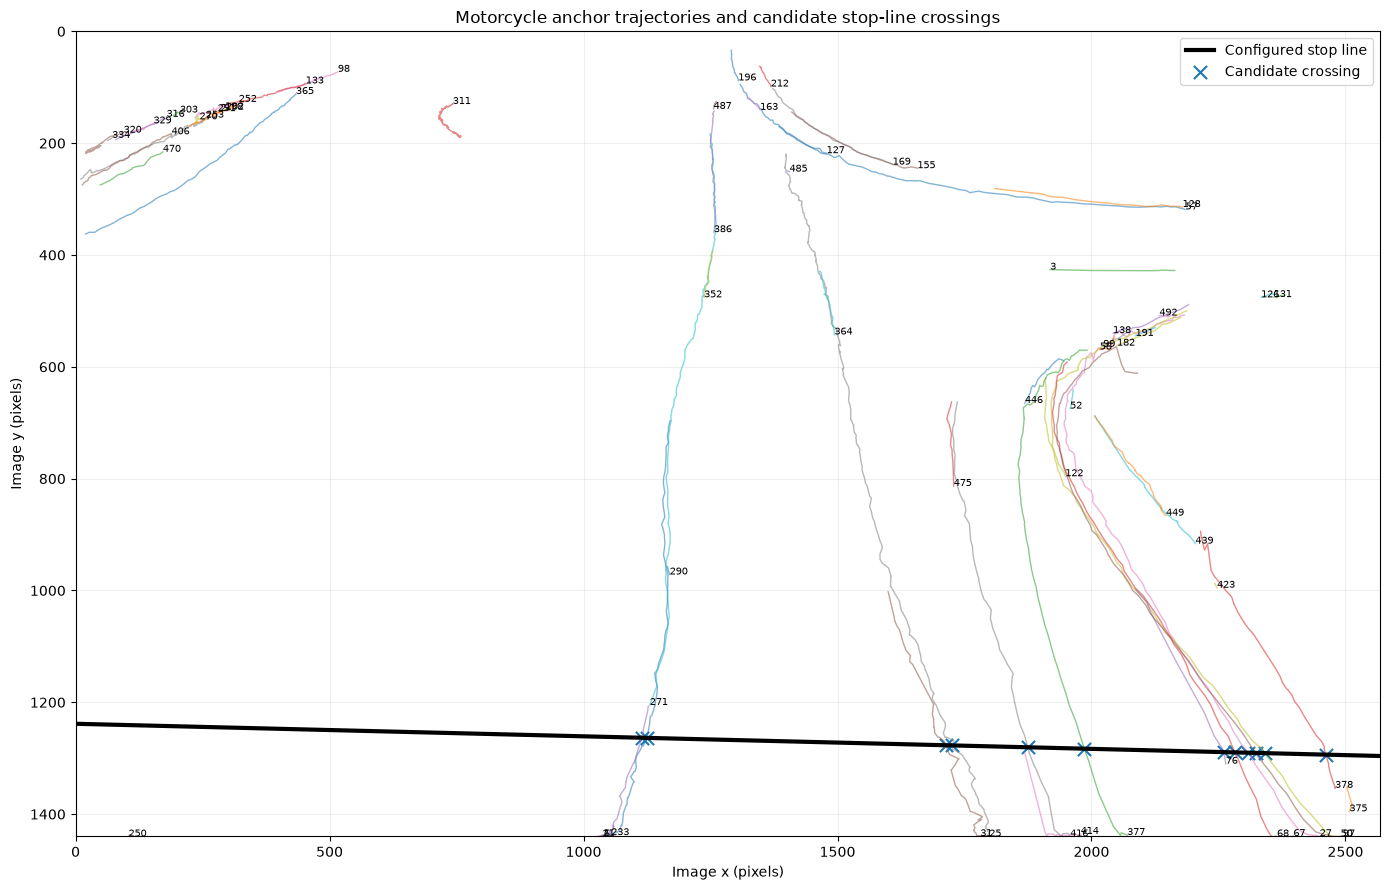

In [15]:
plt.figure(figsize=(14, 9))

for track_id, group in tracks.groupby("track_id"):
    if len(group) < MIN_TRACK_OBSERVATIONS:
        continue
    
    plt.plot(group["anchor_x"], group["anchor_y"], linewidth=1, alpha=0.55)
    first = group.iloc[0]
    plt.text(first["anchor_x"], first["anchor_y"], str(track_id), fontsize=7)

line_x = [LINE_START[0] * width, LINE_END[0] * width]
line_y = [LINE_START[1] * height, LINE_END[1] * height]

plt.plot(line_x, line_y, color="black", linewidth=3, label="Configured stop line")

if not crossings.empty:
    plt.scatter(crossings["crossing_x"], crossings["crossing_y"],
                marker="x", s=90, label="Candidate crossing")

plt.gca().invert_yaxis()
plt.xlim(0, width)
plt.ylim(height, 0)
plt.xlabel("Image x (pixels)")
plt.ylabel("Image y (pixels)")
plt.title("Motorcycle anchor trajectories and candidate stop-line crossings")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.show()

## Review candidate crossings over time

Inspect the crossing timestamps and corresponding video frames manually. A geometric result may be wrong if the track ID switches between vehicles, the anchor is noisy, or the configured line does not match the actual road marking.

,track_id,previous_frame,next_frame,crossing_time_sec,crossing_x,crossing_y,direction
0,27,274,275,9.141195,2308.374701,1290.176629,side_A_to_B
1,50,336,337,11.232774,2340.963491,1290.907592,side_A_to_B
2,68,408,409,13.628316,2282.183272,1289.589158,side_A_to_B
3,76,408,409,13.629332,2260.801180,1289.109559,side_A_to_B
4,97,451,452,15.052179,2322.936288,1290.503244,side_A_to_B
5,25,684,688,22.891031,1712.880621,1276.819752,side_A_to_B
6,31,686,687,22.898999,1726.141148,1277.117185,side_A_to_B
7,1,701,702,23.380934,1124.322145,1263.618441,side_A_to_B
8,21,701,702,23.383248,1114.294432,1263.393520,side_A_to_B
9,378,844,845,28.136528,2461.019325,1293.600433,side_A_to_B


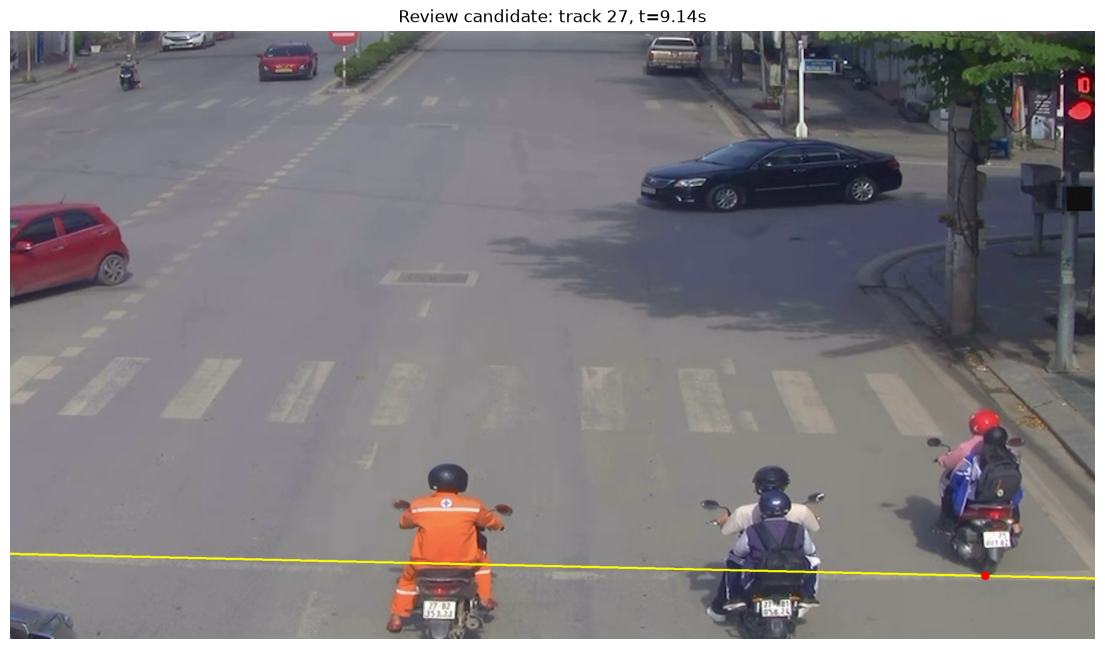

In [16]:
if not crossings.empty:
    crossings = crossings.sort_values("crossing_time_sec").reset_index(drop=True)
    display(crossings)

    # Show a frame near the first candidate crossing with the stop line overlaid.
    selected = crossings.iloc[0]
    review_frame = int(round(selected["crossing_time_sec"] * fps))
    cap = cv2.VideoCapture(str(VIDEO_PATH))
    cap.set(cv2.CAP_PROP_POS_FRAMES, review_frame)
    ok, review = cap.read()
    cap.release()
    
    if ok:
        cv2.line(review, line_px_start, line_px_end, (0, 255, 255), 4)
        cv2.circle(review, (int(selected["crossing_x"]), int(selected["crossing_y"])), 10, (0, 0, 255), -1)
        
        plt.figure(figsize=(14, 8))
        plt.imshow(cv2.cvtColor(review, cv2.COLOR_BGR2RGB))
        plt.title(f"Review candidate: track {int(selected['track_id'])}, t={selected['crossing_time_sec']:.2f}s")
        plt.axis("off")
        plt.show()
else:
    print("No candidate crossings were found. Check the stop-line coordinates, tracking CSV, and track continuity.")